# Bank Account Fraud — Midterm Project Notebook

**Problem.** A bank opening new accounts wants a risk score per application:
high-scored applications are routed to manual review, low-scored ones are
auto-approved. We train a binary classifier on the **Bank Account Fraud (BAF)
dataset** (NeurIPS 2022, Jesus et al., `Base` variant, 1M applications, ~1.1%
fraud rate, CC-BY-NC-SA — semi-synthetic data generated to match a real bank's
distribution).

**Contents:** data prep · EDA · feature importance & leakage audit ·
baseline + tuned model comparison (validation split, 200k subsample) ·
threshold analysis under a review-capacity constraint · temporal holdout
check (the paper's protocol) · final model choice for `train.py`.

**Leakage notes up front:** `device_fraud_count` ("#fraudulent apps on this
device") is checked in the importance audit — it turns out to be constant 0
in this variant, so it is dead weight rather than a leak; kept for schema
consistency. `month` (0–7) is kept: it powers the temporal holdout check.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import features

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
SEED = 42

In [2]:
df = features.load_df()
assert df.shape == (1_000_000, 32), df.shape
print(df.shape)
print(df.dtypes.value_counts())
df.head(3)

(1000000, 32)


int64      18
float64     9
str         5
Name: count, dtype: int64


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0


## 1 · Target distribution — the class imbalance that defines the problem

               share
fraud_bool          
legit       0.988971
fraud       0.011029

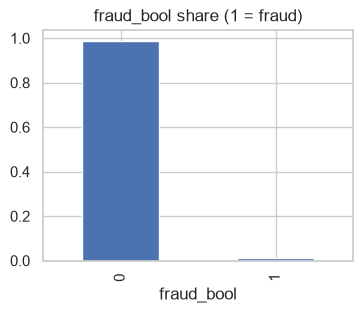

fraud applications: 11,029 of 1,000,000


In [3]:
vc = df[features.TARGET].value_counts(normalize=True)
print(vc.rename({0: "legit", 1: "fraud"}).to_frame("share"))
fig, ax = plt.subplots(figsize=(4, 3))
vc.plot.bar(ax=ax)
ax.set_title("fraud_bool share (1 = fraud)")
plt.show()
print(f"fraud applications: {int(df.fraud_bool.sum()):,} of {len(df):,}")

## 2 · Missing data — `-1` is a sentinel, not a real value

Six columns encode missingness as `-1`. We count sentinel rates and whether
"missingness itself" correlates with fraud (it does in fraud data — missing
info is a risk signal).

                              sentinel_rate  fraud|sentinel  fraud|present
prev_address_months_count            0.7129          0.0142         0.0031
current_address_months_count         0.0043          0.0033         0.0111
credit_risk_score                    0.0005          0.0000         0.0110
bank_months_count                    0.2536          0.0163         0.0092
session_length_in_minutes            0.0020          0.0089         0.0110
device_distinct_emails_8w            0.0004          0.0111         0.0110


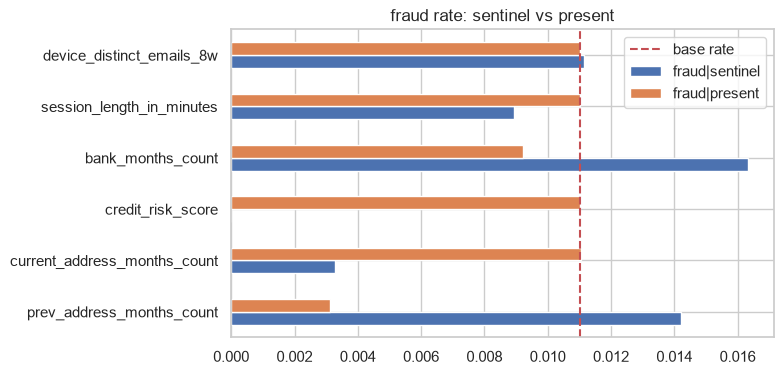


NaN counts (raw): {}


In [4]:
sent = pd.DataFrame({
    "sentinel_rate": [(df[c] == -1).mean() for c in features.SENTINEL_COLS],
    "fraud|sentinel": [df.loc[df[c] == -1, features.TARGET].mean() for c in features.SENTINEL_COLS],
    "fraud|present": [df.loc[df[c] != -1, features.TARGET].mean() for c in features.SENTINEL_COLS],
}, index=features.SENTINEL_COLS)
print(sent.round(4))
sent[["fraud|sentinel", "fraud|present"]].plot.barh(figsize=(7, 4))
plt.axvline(df.fraud_bool.mean(), color="r", ls="--", label="base rate")
plt.legend(); plt.title("fraud rate: sentinel vs present")
plt.show()

# other missingness (true NaN in raw file)
print("\nNaN counts (raw):", df.isna().sum().loc[lambda s: s > 0].to_dict())

## 3 · Numeric feature distributions

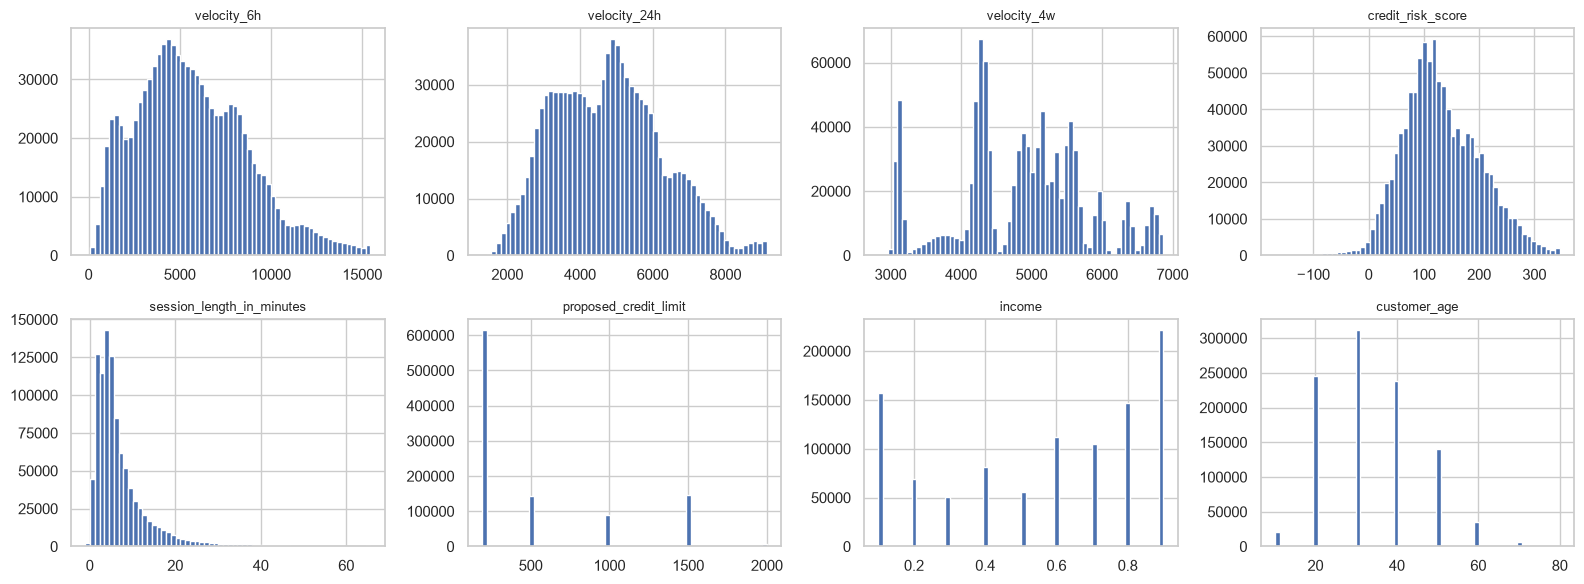

,count,mean,std,min,25%,50%,75%,max
velocity_6h,1000000.0,5665.30,3009.38,-170.60,3436.37,5319.77,7680.72,16715.57
velocity_24h,1000000.0,4769.78,1479.21,1300.31,3593.18,4749.92,5752.57,9506.90
velocity_4w,1000000.0,4856.32,919.84,2825.75,4268.37,4913.44,5488.08,6994.76
credit_risk_score,1000000.0,130.99,69.68,-170.00,83.00,122.00,178.00,389.00
session_length_in_minutes,1000000.0,7.54,8.03,-1.00,3.10,5.11,8.87,85.90
proposed_credit_limit,1000000.0,515.85,487.56,190.00,200.00,200.00,500.00,2100.00
income,1000000.0,0.56,0.29,0.10,0.30,0.60,0.80,0.90
customer_age,1000000.0,33.69,12.03,10.00,20.00,30.00,40.00,90.00


In [5]:
key_num = ["velocity_6h", "velocity_24h", "velocity_4w",
           "credit_risk_score", "session_length_in_minutes",
           "proposed_credit_limit", "income", "customer_age"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.flat, key_num):
    df[c].clip(upper=df[c].quantile(0.999)).hist(bins=60, ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()
df[key_num].describe().T.round(2)

## 4 · Categorical features — levels and per-level fraud rate

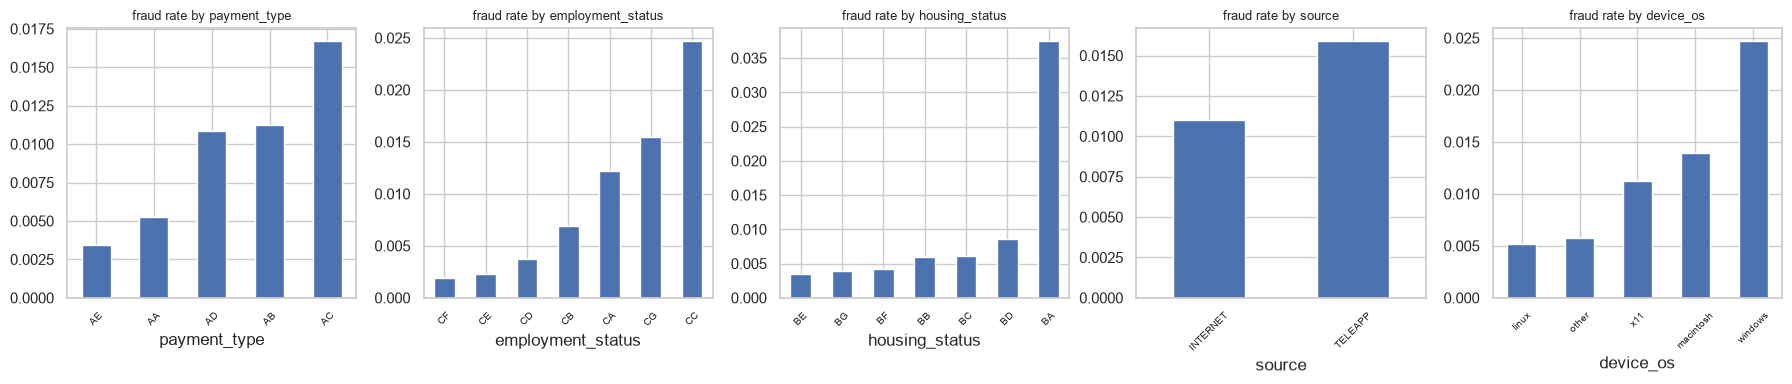

payment_type → {'AB': 370554, 'AA': 258249, 'AC': 252071, 'AD': 118837, 'AE': 289}
employment_status → {'CA': 730252, 'CB': 138288, 'CF': 44034, 'CC': 37758, 'CD': 26522}
housing_status → {'BC': 372143, 'BB': 260965, 'BA': 169675, 'BE': 169135, 'BD': 26161}
source → {'INTERNET': 992952, 'TELEAPP': 7048}
device_os → {'other': 342728, 'linux': 332712, 'windows': 263506, 'macintosh': 53826, 'x11': 7228}


In [6]:
fig, axes = plt.subplots(1, len(features.CATEGORICAL), figsize=(18, 4))
for ax, c in zip(axes, features.CATEGORICAL):
    rate = df.groupby(c)[features.TARGET].mean().sort_values()
    rate.plot.bar(ax=ax)
    ax.set_title(f"fraud rate by {c}", fontsize=9)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
plt.tight_layout(); plt.show()
for c in features.CATEGORICAL:
    print(c, "→", df[c].value_counts().head(5).to_dict())

## 5 · Fraud rate by `month` — also motivates the temporal holdout

        mean   count
month               
0      1.13%  132440
1      0.94%  127620
2      0.87%  136979
3      0.92%  150936
4      1.14%  127691
5      1.18%  119323
6      1.34%  108168
7      1.47%   96843


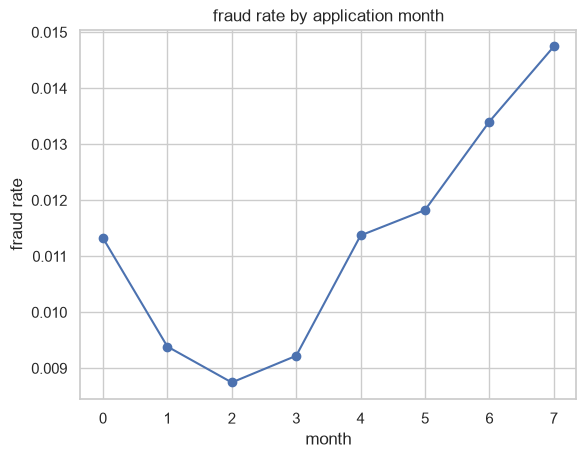

In [7]:
mr = df.groupby("month")[features.TARGET].agg(["mean", "count"])
print(mr.assign(mean=(mr["mean"] * 100).round(2).astype(str) + "%"))
mr["mean"].plot(marker="o", title="fraud rate by application month",
                ylabel="fraud rate")
plt.show()

## 6 · Correlation structure (numerics)

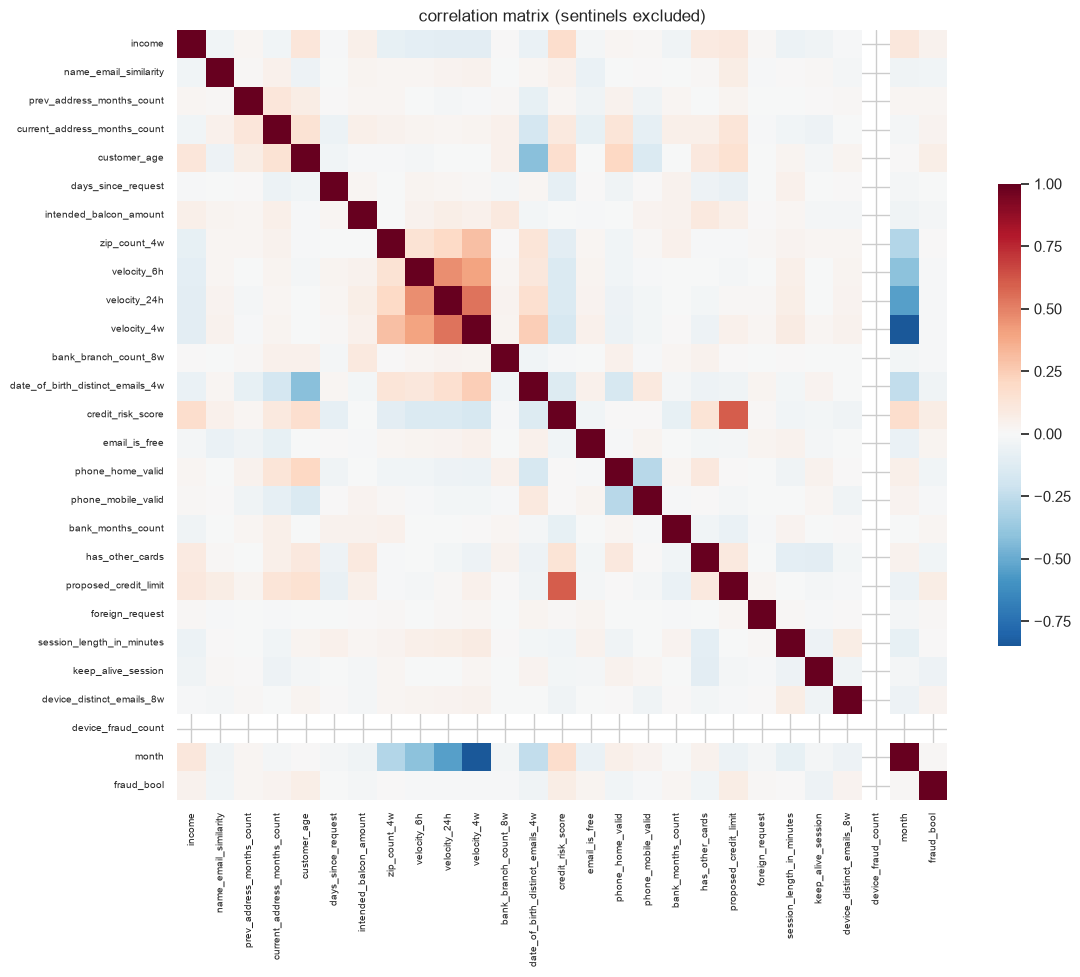

credit_risk_score                   0.070588
proposed_credit_limit               0.068907
customer_age                        0.062959
keep_alive_session                 -0.050296
income                              0.045079
date_of_birth_distinct_emails_4w   -0.043224
name_email_similarity              -0.036720
device_distinct_emails_8w           0.036542
has_other_cards                    -0.035156
phone_home_valid                   -0.035128
Name: fraud_bool, dtype: float64

In [8]:
corr = df[features.NUMERIC + [features.TARGET]].replace(-1, np.nan).corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
ax.tick_params(labelsize=7)
plt.title("correlation matrix (sentinels excluded)")
plt.show()
corr[features.TARGET].drop(features.TARGET).sort_values(
    key=abs, ascending=False).head(10)

## 7 · Mutual information vs target (nonlinear association)

Computed on a 200k stratified subsample; categoricals factorized for MI.

prev_address_months_count    0.0453
keep_alive_session           0.0385
phone_mobile_valid           0.0364
email_is_free                0.0346
employment_status            0.0292
phone_home_valid             0.0229
device_os                    0.0192
payment_type                 0.0165
housing_status               0.0125
proposed_credit_limit        0.0124
customer_age                 0.0119
bank_months_count            0.0093
income                       0.0077
has_other_cards              0.0071
month                        0.0056
dtype: float64


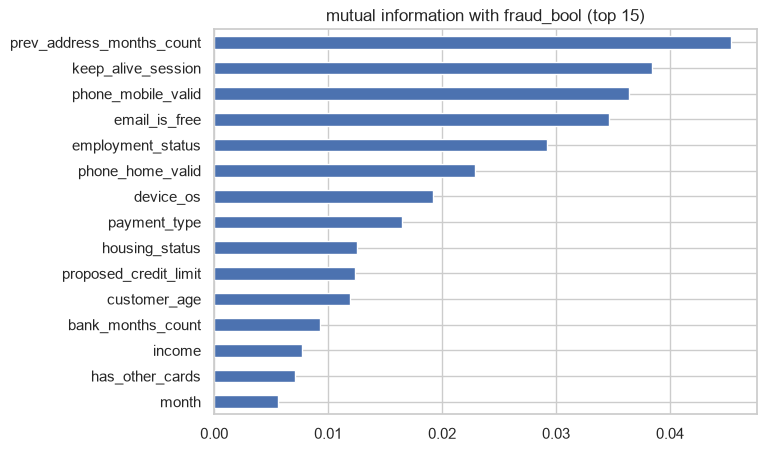

In [9]:
from sklearn.feature_selection import mutual_info_classif

sub = df.sample(200_000, random_state=SEED)
Xmi = sub.drop(columns=[features.TARGET]).copy()
for c in features.SENTINEL_COLS:
    Xmi[c] = Xmi[c].replace(-1, np.nan)
for c in features.CATEGORICAL:
    Xmi[c] = pd.factorize(Xmi[c])[0]
Xmi = Xmi.fillna(-999)
mi = pd.Series(
    mutual_info_classif(Xmi, sub[features.TARGET], random_state=SEED),
    index=Xmi.columns).sort_values(ascending=False)
print(mi.head(15).round(4))
mi.head(15).sort_values().plot.barh(figsize=(7, 5),
    title="mutual information with fraud_bool (top 15)")
plt.show()

## 8 · Feature importance via permutation (fitted RF, 200k subsample)

**Leakage audit:** `device_fraud_count` ("#past fraudulent applications on
this device") would be the prime leak candidate — a bank does see it at
application time, but it summarizes the label itself. Checking it directly:
it is **constant 0 for every row in `Base.csv`**, so it carries no
information and cannot dominate. It is kept (harmless dead weight, honest
about the dataset) rather than silently dropped — but it would need a
second look if this pipeline were ever pointed at the other BAF variants.

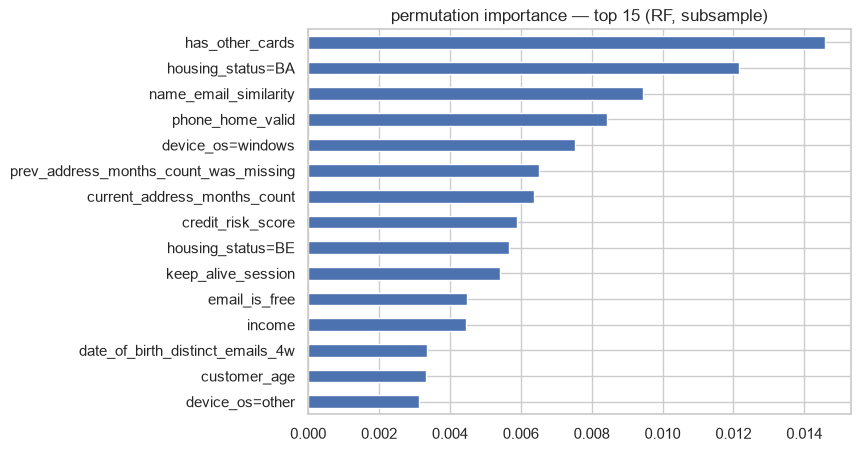

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.inspection import permutation_importance

sub = df.sample(200_000, random_state=SEED)
tr, va, te = features.make_splits(sub)
med = features.medians_of(tr)
trc, vac = features.clean(tr, med), features.clean(va, med)

dv = DictVectorizer(sparse=False)
Xtr = dv.fit_transform(features.to_dicts(trc.drop(columns=[features.TARGET])))
Xva = dv.transform(features.to_dicts(vac.drop(columns=[features.TARGET])))
ytr, yva = trc[features.TARGET].values, vac[features.TARGET].values

rf_audit = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1,
                                  class_weight="balanced", random_state=SEED)
rf_audit.fit(Xtr, ytr)

imp = permutation_importance(rf_audit, Xva[:20_000], yva[:20_000],
                             scoring="average_precision", n_repeats=3,
                             random_state=SEED)
imp_s = pd.Series(imp.importances_mean,
                  index=dv.get_feature_names_out()).sort_values()
imp_s.tail(15).plot.barh(figsize=(7, 5),
    title="permutation importance — top 15 (RF, subsample)")
plt.show()

## 9 · Model comparison — tuned on the 200k subsample, scored on validation

Protocol (matches the design doc): same 60/20/20 split, DictVectorizer fit on
train only, metrics on validation = ROC-AUC, PR-AUC (`average_precision`), and
**recall under a ≤5% review-capacity cap** (a fraud team can only manually
review a few % of applications). Winner is chosen on validation PR-AUC,
tie-broken on recall@cap.

*(Aside on logistic regression: all four C values land on identical validation
metrics — at ~160k training rows regularization strength barely moves the
decision boundary here. The grid is still reported for completeness.)*

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve)
from sklearn.preprocessing import StandardScaler

def recall_at_cap(y, s, cap=0.05):
    k = max(1, int(cap * len(s)))
    flagged = np.argsort(-s)[:k]
    return y[flagged].sum() / y.sum()

def metrics(y, s):
    return dict(roc_auc=roc_auc_score(y, s),
                pr_auc=average_precision_score(y, s),
                recall_at_cap=recall_at_cap(y, s))

rows = []

dummy = DummyClassifier(strategy="prior").fit(Xtr, ytr)
rows.append({"model": "dummy", **metrics(yva, dummy.predict_proba(Xva)[:, 1])})

In [12]:
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xva_s = scaler.transform(Xtr), scaler.transform(Xva)
for C in [0.01, 0.1, 1, 10]:
    lr = LogisticRegression(C=C, max_iter=1500, n_jobs=-1,
                            class_weight="balanced")
    lr.fit(Xtr_s, ytr)
    rows.append({"model": f"logreg C={C}",
                 **metrics(yva, lr.predict_proba(Xva_s)[:, 1])})
    print("lr", C, "done", flush=True)

D:\ai-eng\bank-fraud-detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


lr 0.01 done


D:\ai-eng\bank-fraud-detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


lr 0.1 done


D:\ai-eng\bank-fraud-detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


lr 1 done


D:\ai-eng\bank-fraud-detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


lr 10 done


In [13]:
for depth in [8, 16]:
    for n_est in [100, 200]:
        rf = RandomForestClassifier(n_estimators=n_est, max_depth=depth,
                                    n_jobs=-1, class_weight="balanced",
                                    random_state=SEED)
        rf.fit(Xtr, ytr)
        rows.append({"model": f"rf d={depth} n={n_est}",
                     **metrics(yva, rf.predict_proba(Xva)[:, 1])})
        print("rf", depth, n_est, "done", flush=True)

rf 8 100 done


rf 8 200 done


rf 16 100 done


rf 16 200 done


In [14]:
from xgboost import XGBClassifier

spw = float((ytr == 0).sum() / (ytr == 1).sum())
for depth in [4, 6]:
    for lr_ in [0.05, 0.1]:
        xgb = XGBClassifier(max_depth=depth, learning_rate=lr_,
                            n_estimators=300, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=spw,
                            eval_metric="aucpr", random_state=SEED,
                            n_jobs=-1)
        xgb.fit(Xtr, ytr)
        rows.append({"model": f"xgb d={depth} lr={lr_}",
                     **metrics(yva, xgb.predict_proba(Xva)[:, 1])})
        print("xgb", depth, lr_, "done", flush=True)

xgb 4 0.05 done


xgb 4 0.1 done


xgb 6 0.05 done


xgb 6 0.1 done


In [15]:
res = pd.DataFrame(rows).set_index("model").round(4)
res.sort_values("pr_auc", ascending=False)

,roc_auc,pr_auc,recall_at_cap
model,,,
xgb d=4 lr=0.05,0.8745,0.1225,0.4882
xgb d=4 lr=0.1,0.8664,0.1119,0.4763
xgb d=6 lr=0.05,0.8615,0.1066,0.4573
logreg C=1,0.8698,0.1061,0.4668
logreg C=0.01,0.8701,0.1061,0.4668
logreg C=0.1,0.8698,0.1061,0.4668
logreg C=10,0.8698,0.1061,0.4668
xgb d=6 lr=0.1,0.8389,0.0912,0.4194
rf d=8 n=100,0.8582,0.0843,0.4265


## 10 · Winner + threshold under review-capacity constraint

Winner = best validation PR-AUC (tie-break recall@cap). Threshold policy:
the review team can inspect ~5% of applications → choose the threshold that
**maximizes recall subject to flag-rate ≤ 5%** on validation. F1-optimal
threshold reported alongside.

winner on validation: xgb d=4 lr=0.05


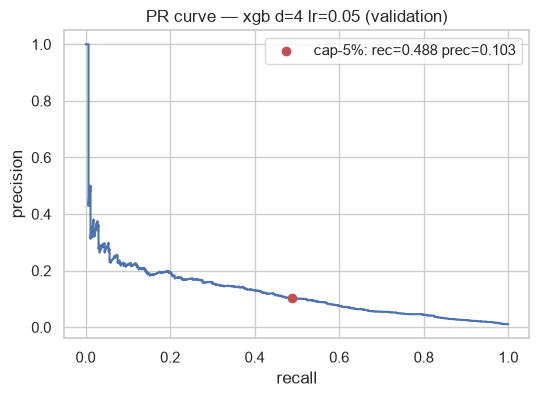

threshold @5% cap = 0.74679  ->  recall 0.488, precision 0.103
threshold @best-F1 = 0.87935  ->  flag rate 1.725%, recall 0.275, precision 0.168


In [16]:
best_name = res.sort_values("pr_auc", ascending=False).index[0]
print("winner on validation:", best_name)

# refit winner spec on the same subsample split (single-config branch)
def fit_winner(Xtr_, ytr_, params=None):
    if best_name.startswith("xgb"):
        d = int(best_name.split("d=")[1][0])
        lr_ = float(best_name.split("lr=")[1])
        m = XGBClassifier(max_depth=d, learning_rate=lr_, n_estimators=300,
                          subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=spw, eval_metric="aucpr",
                          random_state=SEED, n_jobs=-1)
        return m.fit(Xtr_, ytr_), False
    if best_name.startswith("rf"):
        d = int(best_name.split("d=")[1].split()[0])
        n = int(best_name.split("n=")[1])
        m = RandomForestClassifier(n_estimators=n, max_depth=d, n_jobs=-1,
                                   class_weight="balanced", random_state=SEED)
        return m.fit(Xtr_, ytr_), False
    C = float(best_name.split("C=")[1])
    m = LogisticRegression(C=C, max_iter=1500, n_jobs=-1,
                           class_weight="balanced")
    return m.fit(Xtr_s, ytr), True

winner, scaled = fit_winner(Xtr, ytr)
sva = winner.predict_proba(Xva_s if scaled else Xva)[:, 1]

# capacity-constrained threshold: score quantile flagging ~5%
th_cap = float(np.quantile(sva, 0.95))
flag = sva >= th_cap
recall_cap = yva[flag].sum() / yva.sum()
prec_cap = yva[flag].sum() / flag.sum()

prec, rec, ths = precision_recall_curve(yva, sva)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
i_f1 = np.nanargmax(f1)
th_f1 = float(ths[i_f1]) if i_f1 < len(ths) else 0.5

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec, prec)
ax.scatter([recall_cap], [prec_cap], c="r", zorder=5,
           label=f"cap-5%: rec={recall_cap:.3f} prec={prec_cap:.3f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title(f"PR curve — {best_name} (validation)"); ax.legend()
plt.show()
print(f"threshold @5% cap = {th_cap:.5f}  ->  recall {recall_cap:.3f}, "
      f"precision {prec_cap:.3f}")
print(f"threshold @best-F1 = {th_f1:.5f}  ->  "
      f"flag rate {(sva >= th_f1).mean():.3%}, "
      f"recall {yva[sva>=th_f1].sum()/yva.sum():.3f}, "
      f"precision {yva[sva>=th_f1].sum()/max(1,(sva>=th_f1).sum()):.3f}")

## 11 · Temporal holdout — the BAF paper's protocol

Random splits can look inflated when fraud patterns drift. The paper
evaluates temporally: train on months ≤5, test on months 6–7. We refit the
winner's config on the full-data temporal split as a sanity check —
medians are refit on the training period (months <= 5) only, so no
months 6–7 information enters the test features' imputation.

In [17]:
# temporal split FIRST, then medians fit on the train period only
ft_raw = df[df.month <= 5]; tt_raw = df[df.month >= 6]
med_t = features.medians_of(ft_raw)
ft, tt = features.clean(ft_raw, med_t), features.clean(tt_raw, med_t)
print(f"temporal split: train {len(ft):,} (months<=5), "
      f"test {len(tt):,} (months 6-7), fraud rates "
      f"{ft.fraud_bool.mean():.4f} / {tt.fraud_bool.mean():.4f}")

dv_t = DictVectorizer(sparse=False)
Xt_tr = dv_t.fit_transform(
    features.to_dicts(ft.drop(columns=[features.TARGET])))
Xt_tt = dv_t.transform(
    features.to_dicts(tt.drop(columns=[features.TARGET])))
yt_tr, yt_tt = ft[features.TARGET].values, tt[features.TARGET].values

# winner's config (xgb d=4 lr=0.05) — same as train.py's CHOSEN_MODEL
mt = XGBClassifier(max_depth=4, learning_rate=0.05, n_estimators=300,
                   subsample=0.8, colsample_bytree=0.8,
                   scale_pos_weight=float((yt_tr == 0).sum() / (yt_tr == 1).sum()),
                   eval_metric="aucpr", random_state=SEED, n_jobs=-1)
mt.fit(Xt_tr, yt_tr)
stt = mt.predict_proba(Xt_tt)[:, 1]
print(metrics(yt_tt, stt))

temporal split: train 794,989 (months<=5), test 205,011 (months 6-7), fraud rates 0.0103 / 0.0140


{'roc_auc': 0.8945502883051767, 'pr_auc': 0.1975873856069751, 'recall_at_cap': np.float64(0.5208478109798471)}


## 12 · Conclusion — what `train.py` will do

- Winner model + params are read off the comparison table above and
  hard-coded as `CHOSEN_MODEL` in `train.py` (no search inside the script).
- `train.py` refits on train+val of the full 1M with the same cleaning
  (train-split medians stored in the artifact), evaluates once on the held
  test split at the capacity-derived threshold, and pickles
  `{model, dv, threshold, features, medians, metrics}` to `model.bin`.
- Deployment serves `fraud_score` (rank-consistent score) + `decision`
  (score ≥ threshold). Calibration to true probabilities is future work.